# Tarea 1 – Parte 2 – Del LLM al clasificador: titulares de **El Comercio** (Caso B)

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Se parte de `datos/noticias.csv` (394 titulares de El Comercio recolectados en la Parte 1). La columna `etiqueta` es la categoría derivada de la **sección editorial** de cada nota: es la referencia contra la que se mide todo. Se comparan tres enfoques sobre **el mismo conjunto de test aislado**:

| Sección | Paso del enunciado | Qué se hace | Resultado |
|---|---|---|---|
| 1 | Paso 3 | Partición estratificada 70/15/15 con `random_state=42`. **Se hace primero** para que ninguna decisión posterior mire el test | `datos/particion.csv` |
| 2 | Paso 1 | Línea base zero-shot (sin entrenamiento) sobre 40 titulares | Piso mínimo de F1 macro |
| 3 | Paso 2 | Supervisión débil: un LLM local (Qwen2.5) etiqueta los 394 titulares con un prompt estructurado + auditoría humana de 20 casos | `datos/etiquetas_llm.csv`, `datos/auditoria_llm.csv` |
| 4 | Paso 4 | Fine-tuning de `distilbert-base-multilingual-cased` con `Trainer` (F1 macro por época) | `modelo/` |
| 5 | Paso 5 | Evaluación final en test: accuracy, F1 macro, matriz de confusión y reflexión por categoría | Métricas finales |
| 6 | Paso 6 | Comparativa zero-shot vs. LLM vs. fine-tuned y decisión para producción | Tabla + justificación |

**Entorno:** todo corre en **CPU** (Intel i7-3770S, 4 núcleos, 16 GB de RAM, sin GPU), sin APIs de pago ni claves.

**Regla del test:** las noticias de test no se usan para entrenar, elegir épocas, elegir modelos ni diseñar el prompt; solo se miden en las secciones 5 y 6.

## 0. Configuración

- **Dependencias:** `pandas`, `numpy`, `scikit-learn`, `torch` (CPU), `transformers`, `accelerate` (lo usa `Trainer`), `seaborn` y `matplotlib` (los gráficos quedan como imagen y se ven en GitHub).
- **`USAR_CACHE = True`:** si `datos/etiquetas_llm.csv` ya existe se reutiliza, porque etiquetar con el LLM en esta CPU tarda varios minutos; con `False` se vuelve a etiquetar todo. La auditoría humana (`datos/auditoria_llm.csv`) **nunca** se sobrescribe.
- Los modelos se descargan de Hugging Face la primera vez y quedan en la caché local.

In [1]:
import copy
import gc
import json
import os
import platform
import random
import shutil
import tempfile
import time
import warnings
from datetime import datetime
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")   # aviso de tqdm al importar transformers

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from transformers.utils import logging as hf_logging

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore", category=FutureWarning)
hf_logging.set_verbosity_error()      # oculta avisos de carga de pesos
hf_logging.disable_progress_bar()

SEMILLA = 42
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]   # mismo orden que en la Parte 1
DATOS, MODELO = Path("datos"), Path("modelo")
MODELO.mkdir(exist_ok=True)
USAR_CACHE = True

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(4)              # 4 núcleos físicos
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)


def metricas(y_true, y_pred):
    # F1 macro: promedio simple del F1 de cada categoría (todas pesan igual)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(y_true, y_pred, labels=ETIQUETAS, average="macro")}


noticias = pd.read_csv(DATOS / "noticias.csv")
print(f"CPU: {platform.processor()} | hilos torch: {torch.get_num_threads()} | "
      f"torch {torch.__version__} | transformers {transformers.__version__}")
print("noticias.csv:", noticias.shape)
noticias["etiqueta"].value_counts().to_frame("noticias")

CPU: Intel64 Family 6 Model 58 Stepping 9, GenuineIntel | hilos torch: 4 | torch 2.14.1+cpu | transformers 5.20.1
noticias.csv: (394, 7)


,noticias
etiqueta,
politica,100
economia,100
deportes,99
ciencia_tecnologia,95


## 1. Partición estratificada 70 / 15 / 15 (paso 3 del enunciado)

Dos cortes estratificados por `etiqueta`, ambos con `random_state=42`: primero se aparta el **15 % de test**; del 85 % restante se separa validación con `test_size=0.15/0.85` (≈ 15 % del total). Así cada partición conserva la proporción de categorías.

- **train:** entrena el Transformer.
- **val:** elige la mejor época y el mejor modelo (y es donde se mira el desempeño mientras se desarrolla).
- **test:** queda guardado hasta la sección 5.

La partición se guarda en `datos/particion.csv` (por URL) para que el dashboard y cualquier re-ejecución usen exactamente las mismas noticias. A las noticias de train + val se les llama **desarrollo**: es lo único que se usa para diseñar y comparar antes de la evaluación final.

In [2]:
resto, test_df = train_test_split(noticias, test_size=0.15, stratify=noticias["etiqueta"], random_state=SEMILLA)
train_df, val_df = train_test_split(resto, test_size=0.15 / 0.85, stratify=resto["etiqueta"], random_state=SEMILLA)

noticias["particion"] = "train"
noticias.loc[val_df.index, "particion"] = "val"
noticias.loc[test_df.index, "particion"] = "test"


def particion(*nombres):
    # Filas de `noticias` (con todas sus columnas actuales) que pertenecen a las particiones pedidas
    return noticias[noticias["particion"].isin(nombres)]


# Comprobaciones: particiones disjuntas que cubren todo el dataset
urls = {p: set(particion(p)["url"]) for p in ["train", "val", "test"]}
assert not (urls["train"] & urls["val"]) and not (urls["train"] & urls["test"]) and not (urls["val"] & urls["test"])
assert sum(len(u) for u in urls.values()) == len(noticias)

noticias[["url", "titular", "etiqueta", "particion"]].to_csv(DATOS / "particion.csv", index=False, encoding="utf-8")

tabla_split = pd.crosstab(noticias["etiqueta"], noticias["particion"], margins=True, margins_name="total")
tabla_split = tabla_split[["train", "val", "test", "total"]].reindex(ETIQUETAS + ["total"])
tabla_split.loc["% del total"] = (tabla_split.loc["total"] / len(noticias) * 100).round(1)
tabla_split

particion,train,val,test,total
etiqueta,,,,
politica,70.0,15.0,15.0,100.0
economia,70.0,15.0,15.0,100.0
deportes,69.0,15.0,15.0,99.0
ciencia_tecnologia,66.0,14.0,15.0,95.0
total,275.0,59.0,60.0,394.0
% del total,69.8,15.0,15.2,100.0


## 2. Línea base zero-shot, sin fine-tuning (paso 1)

Un modelo de **inferencia en lenguaje natural (NLI)** decide si un texto implica una hipótesis. Para clasificar sin entrenar, cada categoría se convierte en una hipótesis, *"Esta noticia trata sobre {categoría}."*, y gana la categoría con mayor probabilidad de implicación.

- **40 titulares:** 10 por categoría, al azar (`random_state=42`), tomados del conjunto de **desarrollo**, no del test (en la sección 6 el mejor zero-shot se mide además sobre el test, para compararlo con los demás en igualdad de condiciones).
- Se prueban los **dos modelos sugeridos** con la misma plantilla y las mismas etiquetas en español. La plantilla se fijó de antemano y no se ajustó mirando resultados.

In [3]:
from transformers import pipeline

MODELOS_ZS = ["joeddav/xlm-roberta-large-xnli", "Recognai/bert-base-spanish-wwm-cased-xnli"]
ETIQ_ZS = {"politica": "política", "economia": "economía", "deportes": "deportes",
           "ciencia_tecnologia": "ciencia y tecnología"}
INV_ZS = {v: k for k, v in ETIQ_ZS.items()}
PLANTILLA_ZS = "Esta noticia trata sobre {}."

muestra_zs = particion("train", "val").groupby("etiqueta").sample(10, random_state=SEMILLA).copy()


def zero_shot(clf, titulares):
    salida = clf(list(titulares), candidate_labels=list(ETIQ_ZS.values()),
                 hypothesis_template=PLANTILLA_ZS, batch_size=8)
    return [INV_ZS[s["labels"][0]] for s in salida], [s["scores"][0] for s in salida]


resultados_zs, preds_zs = [], {}
for nombre in MODELOS_ZS:
    clf = pipeline("zero-shot-classification", model=nombre, device=-1)
    inicio = time.time()
    preds_zs[nombre], _ = zero_shot(clf, muestra_zs["titular"])
    segundos = time.time() - inicio
    resultados_zs.append({"modelo": nombre, **metricas(muestra_zs["etiqueta"], preds_zs[nombre]),
                          "seg_por_titular": segundos / len(muestra_zs),
                          "parametros_M": sum(p.numel() for p in clf.model.parameters()) / 1e6})
    del clf
    gc.collect()

resultados_zs = pd.DataFrame(resultados_zs).sort_values("f1_macro", ascending=False).reset_index(drop=True)
MEJOR_ZS = resultados_zs.loc[0, "modelo"]
F1_ZS_40 = resultados_zs.loc[0, "f1_macro"]
display(resultados_zs.round(3))
print(f"Piso mínimo a superar (zero-shot, 40 titulares): F1 macro = {F1_ZS_40:.3f} "
      f"| accuracy = {resultados_zs.loc[0, 'accuracy']:.3f} | modelo: {MEJOR_ZS}")

,modelo,accuracy,f1_macro,seg_por_titular,parametros_M
0,joeddav/xlm-roberta-large-xnli,0.700,0.694,2.031,559.894
1,Recognai/bert-base-spanish-wwm-cased-xnli,0.575,0.535,0.484,109.853


Piso mínimo a superar (zero-shot, 40 titulares): F1 macro = 0.694 | accuracy = 0.700 | modelo: joeddav/xlm-roberta-large-xnli


In [4]:
# ¿Dónde se equivoca el mejor zero-shot? (recall por categoría y errores)
muestra_zs["pred_zs"] = preds_zs[MEJOR_ZS]
print("Aciertos por categoría (de 10):",
      muestra_zs.assign(ok=muestra_zs["pred_zs"].eq(muestra_zs["etiqueta"]))
      .groupby("etiqueta")["ok"].sum().reindex(ETIQUETAS).to_dict())
errores_zs = muestra_zs.loc[muestra_zs["pred_zs"] != muestra_zs["etiqueta"], ["etiqueta", "pred_zs", "titular"]]
print(f"Errores: {len(errores_zs)} de {len(muestra_zs)}")
errores_zs.reset_index(drop=True)

Aciertos por categoría (de 10): {'politica': 7, 'economia': 4, 'deportes': 9, 'ciencia_tecnologia': 8}


Errores: 12 de 40


,etiqueta,pred_zs,titular
0,ciencia_tecnologia,economia,La nostalgia vuelve a encenderse: Atari relanza su computadora de 1983 con 25 juegos clásicos
1,ciencia_tecnologia,economia,Estafas digitales contra adultos mayores: seis recomendaciones para proteger a padres y abuelos
2,deportes,economia,“Estaba en el banquillo hablando con Dios”: Endrick explica cómo vivió su ingreso ante la Roma
3,economia,deportes,BTS en Perú: 15 operaciones aéreas y cerca de 1.000 toneladas de carga detrás de sus conciertos
4,economia,deportes,Precio del dólar en Perú: a cuánto cerró el tipo de cambio el martes 13 de octubre
5,economia,deportes,"El precio del petróleo de Texas sube un leve 0,11%, hasta los US$95,19 el barril"
6,economia,ciencia_tecnologia,IA y Sandbox regulatorio
7,economia,ciencia_tecnologia,"De consultar saldos a delegar operaciones, ¿cómo cambiará la banca con la IA hacia 2030?"
8,economia,ciencia_tecnologia,Interseguro sobre incidente de ciberseguridad: “El 7 de octubre detectamos el acceso no autorizado del cib...
9,politica,deportes,Más de mil actas observadas siguen en trámite y extienden definición por la Alcaldía de Lima


**Lectura del zero-shot.** `xlm-roberta-large-xnli` (560 M de parámetros) supera con claridad al BETO-XNLI (F1 0.69 vs. 0.54), así que es la línea base. El **piso a superar es F1 macro = 0.69**. Sus errores muestran que el NLI se guía por palabras sueltas y no por el tema:

- **"IA", "ciberseguridad" o "digitales" arrastran a `ciencia_tecnologia`** aunque la nota sea de banca, seguros o regulación (*"IA y Sandbox regulatorio"*, *"Interseguro sobre incidente de ciberseguridad"*).
- **Cifras y precios se confunden con deportes** (*"Precio del dólar…"*, *"El precio del petróleo de Texas sube…"*): números, alzas y bajas recuerdan marcadores y resultados.
- **La cobertura electoral que no dice "política"** (*"actas observadas"*, *"Resultados ONPE al 95.420 %"*) sale como deportes o economía.

Economía es la categoría más difícil sin entrenamiento (4 de 10): es la más heterogénea y su vocabulario se cruza con todas las demás.

## 3. Supervisión débil con un LLM local (paso 2)

**LLM elegido:** `Qwen/Qwen2.5-1.5B-Instruct` (Alibaba, licencia Apache 2.0, entrenado en ~30 idiomas incluido el español), ejecutado **localmente en CPU** con `transformers`. Ventajas frente a una API: costo cero, ningún dato sale de la máquina, no hace falta clave y el resultado es reproducible. Es un modelo pequeño (1.500 M de parámetros) porque esta CPU no tiene GPU ni instrucciones bf16; uno de 7 B no cabría en la RAM libre.

**Prompt estructurado** (mensaje de sistema, se muestra abajo): rol, definición operativa de cada categoría, reglas, 4 ejemplos **inventados** (no salen del dataset, para no filtrar etiquetas reales) y formato de salida JSON obligatorio `{"categoria": "..."}`. El mensaje de usuario es `Titular: <titular>`.

**Decodificación restringida y confianza.** En vez de dejar que el modelo escriba texto libre (que podría salir mal formado o inventar una 5.ª categoría), la respuesta se fija hasta `{"categoria": "` y se lee la distribución de probabilidad del siguiente token **solo entre las 4 opciones válidas** (sus primeros tokens son distintos, así que elegir el primer token equivale a elegir la categoría). Entonces:

- `etiqueta_llm` = la categoría más probable (decodificación *greedy*, determinista);
- `confianza` = su probabilidad renormalizada entre las 4 opciones: es una probabilidad del modelo, no un número "autodeclarado" por el LLM.

¿Es válido mirar solo el primer token? Los primeros tokens son `polit`, `e`, `de` y `ci`, y `de` es un prefijo muy común en español, así que podría "robar" probabilidad. Se verificó en **desarrollo** (nunca en test) comparándolo con puntuar la palabra completa de cada categoría (`polit·ica`, `e·conom·ia`, `de·port·es`, `ci·encia·_t·ecn·ologia`, como hace *lm-evaluation-harness* en opción múltiple): primero con 20 titulares de entrenamiento y luego con 119 de desarrollo (todos los desacuerdos con la etiqueta editorial más 60 acuerdos al azar). **Las predicciones fueron idénticas en los 139 casos** y las confianzas difirieron en ±0.01, pero puntuar la palabra completa cuesta 4.5 s por titular en lugar de 2.7 s. Por eso basta una pasada del modelo por titular.

**Eficiencia:** el mensaje de sistema es idéntico para todos los titulares, así que su caché de atención (KV cache) se calcula una sola vez y se reutiliza; por titular solo se procesan ~40 tokens (≈2.7 s en esta CPU, ≈17 min para los 394).

**Entrada:** solo el titular, igual que los otros modelos y que el dashboard.

In [5]:
MODELO_LLM = "Qwen/Qwen2.5-1.5B-Instruct"
PROMPT_SISTEMA = """Eres un editor de un diario peruano. Tu tarea es clasificar el titular de una noticia en exactamente UNA de estas 4 categorías:

- politica: gobierno y Poder Ejecutivo, Congreso (Senado y Cámara de Diputados), partidos y candidatos, elecciones (ONPE, JNE), ministros y autoridades, justicia, fiscalía y corrupción de funcionarios, política exterior y diplomacia.
- economia: economía peruana y mundial, empresas y negocios, mercados, bolsa, banca y finanzas, inversión, comercio y exportaciones, minería, energía e hidrocarburos como actividad económica, empleo, sueldos, impuestos, precios y consumo.
- deportes: fútbol (Liga 1, selección peruana, clubes, torneos internacionales), otros deportes, deportistas, partidos, resultados, fichajes y competencias.
- ciencia_tecnologia: ciencia e investigación, salud y medicina, espacio y astronomía, medio ambiente y animales, inteligencia artificial, empresas tecnológicas, celulares, aplicaciones, internet, ciberseguridad y videojuegos.

Reglas:
1. Elige la categoría del tema principal del titular, aunque mencione otros temas.
2. Usa solo una de las 4 categorías; no inventes otras.
3. Responde únicamente con un JSON válido, sin explicaciones: {"categoria": "<politica|economia|deportes|ciencia_tecnologia>"}

Ejemplos:
Titular: Pleno del Congreso aprueba en primera votación la reforma del sistema electoral
{"categoria": "politica"}
Titular: BCR mantiene su tasa de referencia y prevé que la inflación cierre el año en 2 %
{"categoria": "economia"}
Titular: Universitario venció a Sporting Cristal y se acerca al título del Torneo Clausura
{"categoria": "deportes"}
Titular: Científicos descubren una nueva especie de rana en la Amazonía peruana
{"categoria": "ciencia_tecnologia"}"""

print(PROMPT_SISTEMA)

Eres un editor de un diario peruano. Tu tarea es clasificar el titular de una noticia en exactamente UNA de estas 4 categorías:

- politica: gobierno y Poder Ejecutivo, Congreso (Senado y Cámara de Diputados), partidos y candidatos, elecciones (ONPE, JNE), ministros y autoridades, justicia, fiscalía y corrupción de funcionarios, política exterior y diplomacia.
- economia: economía peruana y mundial, empresas y negocios, mercados, bolsa, banca y finanzas, inversión, comercio y exportaciones, minería, energía e hidrocarburos como actividad económica, empleo, sueldos, impuestos, precios y consumo.
- deportes: fútbol (Liga 1, selección peruana, clubes, torneos internacionales), otros deportes, deportistas, partidos, resultados, fichajes y competencias.
- ciencia_tecnologia: ciencia e investigación, salud y medicina, espacio y astronomía, medio ambiente y animales, inteligencia artificial, empresas tecnológicas, celulares, aplicaciones, internet, ciberseguridad y videojuegos.

Reglas:
1. El

In [6]:
from transformers import AutoModelForCausalLM, AutoTokenizer

ETIQ_LLM_CSV = DATOS / "etiquetas_llm.csv"
META_LLM = DATOS / "etiquetas_llm_meta.json"


class EtiquetadorLLM:
    """Clasifica un titular con el LLM forzando la salida JSON y leyendo la prob. de las 4 categorías."""

    def __init__(self, nombre, sistema):
        self.tok = AutoTokenizer.from_pretrained(nombre)
        self.modelo = AutoModelForCausalLM.from_pretrained(nombre, dtype=torch.float32).eval()
        marca = "<<TITULAR>>"
        texto = self.tok.apply_chat_template(
            [{"role": "system", "content": sistema}, {"role": "user", "content": f"Titular: {marca}"}],
            tokenize=False, add_generation_prompt=True)
        self.antes, self.despues = texto.split(marca)
        # Tokens de las 4 respuestas válidas: parte común (se fuerza) + primer token distinto de cada una
        resp = [self.tok.encode(f'{{"categoria": "{e}"}}', add_special_tokens=False) for e in ETIQUETAS]
        n = 0
        while all(r[n] == resp[0][n] for r in resp):
            n += 1
        self.forzado, self.primeros = resp[0][:n], [r[n] for r in resp]
        assert len(set(self.primeros)) == len(ETIQUETAS), "las categorías deben empezar con tokens distintos"
        with torch.inference_mode():
            ids = torch.tensor([self.tok.encode(self.antes, add_special_tokens=False)])
            self.cache_sistema = self.modelo(ids, use_cache=True).past_key_values
        self.n_tokens_sistema = ids.shape[1]

    @torch.inference_mode()
    def clasificar(self, titular):
        ids = self.tok.encode(titular + self.despues, add_special_tokens=False) + self.forzado
        salida = self.modelo(torch.tensor([ids]), past_key_values=copy.deepcopy(self.cache_sistema), use_cache=True)
        prob = torch.softmax(salida.logits[0, -1, self.primeros].float(), dim=0)
        k = int(prob.argmax())
        return ETIQUETAS[k], float(prob[k])


if USAR_CACHE and ETIQ_LLM_CSV.exists() and META_LLM.exists():
    etiquetas_llm = pd.read_csv(ETIQ_LLM_CSV)
    meta_llm = json.loads(META_LLM.read_text(encoding="utf-8"))
    assert meta_llm["modelo_llm"] == MODELO_LLM and meta_llm["prompt_sistema"] == PROMPT_SISTEMA
    print(f"Etiquetas cargadas de caché ({ETIQ_LLM_CSV}), generadas el {meta_llm['fecha']}")
else:
    llm = EtiquetadorLLM(MODELO_LLM, PROMPT_SISTEMA)
    print(f"Respuesta forzada: {llm.tok.decode(llm.forzado)!r} | primeros tokens de cada categoría: "
          f"{llm.tok.convert_ids_to_tokens(llm.primeros)} | prompt de sistema: {llm.n_tokens_sistema} tokens")
    filas, inicio = [], time.time()
    for i, titular in enumerate(noticias["titular"], 1):
        etiqueta, confianza = llm.clasificar(titular)
        filas.append({"titular": titular, "etiqueta_llm": etiqueta, "confianza": round(confianza, 4),
                      "modelo_llm": MODELO_LLM, "fecha": datetime.now().strftime("%Y-%m-%d %H:%M:%S")})
        if i % 50 == 0 or i == len(noticias):
            print(f"  {i}/{len(noticias)} ({time.time() - inicio:.0f} s)")
    segundos = time.time() - inicio
    etiquetas_llm = pd.DataFrame(filas)
    etiquetas_llm.to_csv(ETIQ_LLM_CSV, index=False, encoding="utf-8")
    meta_llm = {"modelo_llm": MODELO_LLM, "dtype": "float32", "dispositivo": "cpu", "n_titulares": len(filas),
                "segundos_total": round(segundos, 1), "seg_por_titular": round(segundos / len(filas), 3),
                "fecha": datetime.now().isoformat(timespec="seconds"), "prompt_sistema": PROMPT_SISTEMA}
    META_LLM.write_text(json.dumps(meta_llm, ensure_ascii=False, indent=2), encoding="utf-8")
    del llm
    gc.collect()

print(f"{meta_llm['n_titulares']} titulares en {meta_llm['segundos_total'] / 60:.1f} min "
      f"({meta_llm['seg_por_titular']:.2f} s por titular, CPU)")
assert list(etiquetas_llm.columns) == ["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha"]
assert etiquetas_llm["titular"].tolist() == noticias["titular"].tolist()
assert etiquetas_llm["etiqueta_llm"].isin(ETIQUETAS).all()
etiquetas_llm.head()

Etiquetas cargadas de caché (datos\etiquetas_llm.csv), generadas el 2026-10-17T12:23:35
394 titulares en 17.4 min (2.65 s por titular, CPU)


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,"Físico, compromiso y entorno: las razones que alejaron a Piero Cari de Pablo Guede y por qué hoy Alianza v...",deportes,0.7970,Qwen/Qwen2.5-1.5B-Instruct,2026-10-17 12:06:16
1,"De Kluiverth en Alianza a Osorio de la ‘U’: la Liga 1 vendió 18 promesas a Europa desde 2020, pero casi la...",deportes,0.9922,Qwen/Qwen2.5-1.5B-Instruct,2026-10-17 12:06:20
2,Renovación Popular se declara en reorganización partidaria: ¿A qué se debe y cuáles son los alcances de la...,politica,0.9928,Qwen/Qwen2.5-1.5B-Instruct,2026-10-17 12:06:23
3,Facultades legislativas: Senado sigue sin alcanzar consenso y debate continúa entrampado,politica,0.9976,Qwen/Qwen2.5-1.5B-Instruct,2026-10-17 12:06:25
4,Los Chankas derrotó 2-1 a ADT por la fecha 12 del Torneo Clausura de la Liga 1 2026,deportes,0.9999,Qwen/Qwen2.5-1.5B-Instruct,2026-10-17 12:06:28


### 3.1 ¿Qué tan cerca está el LLM de la etiqueta editorial? (solo desarrollo)

Se compara `etiqueta_llm` con `etiqueta` **solo en train + val**; su desempeño en test se mide recién en la sección 6. También se revisa si la `confianza` sirve para algo: si el acuerdo crece con la confianza, la confianza es informativa.

LLM vs. etiqueta editorial en desarrollo (n=334): accuracy = 0.823 | F1 macro = 0.818



Acuerdo con la etiqueta editorial según la confianza del LLM:


,noticias,acuerdo
tramo,,
"(-0.001, 0.6]",32,44%
"(0.6, 0.8]",44,59%
"(0.8, 0.95]",65,80%
"(0.95, 1.0]",193,95%


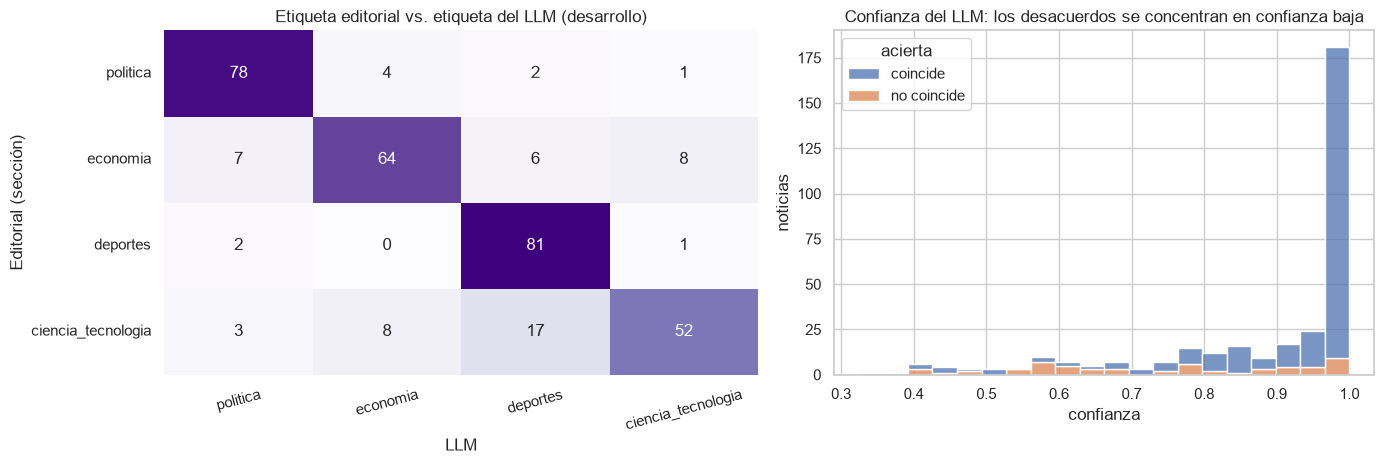

In [7]:
noticias["etiqueta_llm"] = etiquetas_llm["etiqueta_llm"].values
noticias["confianza_llm"] = etiquetas_llm["confianza"].values
dev = particion("train", "val")

m_llm_dev = metricas(dev["etiqueta"], dev["etiqueta_llm"])
print(f"LLM vs. etiqueta editorial en desarrollo (n={len(dev)}): "
      f"accuracy = {m_llm_dev['accuracy']:.3f} | F1 macro = {m_llm_dev['f1_macro']:.3f}")

tramos = pd.cut(dev["confianza_llm"], [0, 0.6, 0.8, 0.95, 1.0], include_lowest=True)
por_tramo = (dev.assign(acuerdo=dev["etiqueta_llm"].eq(dev["etiqueta"]), tramo=tramos)
             .groupby("tramo", observed=True)["acuerdo"].agg(noticias="size", acuerdo="mean"))
print("\nAcuerdo con la etiqueta editorial según la confianza del LLM:")
display(por_tramo.style.format({"acuerdo": "{:.0%}"}))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
cruce = pd.crosstab(dev["etiqueta"], dev["etiqueta_llm"]).reindex(index=ETIQUETAS, columns=ETIQUETAS, fill_value=0)
sns.heatmap(cruce, annot=True, fmt="d", cmap="Purples", cbar=False, ax=ejes[0])
ejes[0].set(title="Etiqueta editorial vs. etiqueta del LLM (desarrollo)", xlabel="LLM", ylabel="Editorial (sección)")
ejes[0].tick_params(axis="y", labelrotation=0)
ejes[0].tick_params(axis="x", labelrotation=15)
sns.histplot(data=dev.assign(acierta=dev["etiqueta_llm"].eq(dev["etiqueta"]).map({True: "coincide", False: "no coincide"})),
             x="confianza_llm", hue="acierta", bins=20, multiple="stack", ax=ejes[1])
ejes[1].set(title="Confianza del LLM: los desacuerdos se concentran en confianza baja",
            xlabel="confianza", ylabel="noticias")
plt.tight_layout()
plt.show()

In [8]:
# Desacuerdos más "seguros" del LLM: ¿error del LLM o noticia publicada en una sección que no es su tema?
desacuerdos = dev[dev["etiqueta_llm"] != dev["etiqueta"]].sort_values("confianza_llm", ascending=False)
print(f"Desacuerdos en desarrollo: {len(desacuerdos)} de {len(dev)}")
desacuerdos[["etiqueta", "etiqueta_llm", "confianza_llm", "titular"]].head(12).round(3).reset_index(drop=True)

Desacuerdos en desarrollo: 59 de 334


,etiqueta,etiqueta_llm,confianza_llm,titular
0,economia,ciencia_tecnologia,0.999,Creación de agentes de IA se multiplicó por 15 en el último año: ¿cómo impacta en la productividad empresa...
1,economia,ciencia_tecnologia,0.998,IA y Sandbox regulatorio
2,economia,ciencia_tecnologia,0.987,Interseguro sobre incidente de ciberseguridad: “El 7 de octubre detectamos el acceso no autorizado del cib...
3,ciencia_tecnologia,deportes,0.987,Tesla presenta un Roadster capaz de ‘volar’ y en las redes sociales lo reciben con memes
4,economia,politica,0.984,Gobierno designa presidenta del directorio y directora ejecutiva del Fonafe
5,ciencia_tecnologia,deportes,0.982,"Sortean una réplica exacta del auto de “Street Fighter II”, pixeles incluídos"
6,ciencia_tecnologia,economia,0.982,Menos comida y más cara: El Niño amenaza los alimentos y la pesca en Latinoamérica
7,ciencia_tecnologia,deportes,0.981,"GTA V: ejecutan el videojuego gratis en un navegador, pero desaparece en pocas horas"
8,ciencia_tecnologia,deportes,0.974,"“Grand Theft Auto VI” vuelve con tráiler lleno de acción, robos y sexo"
9,ciencia_tecnologia,deportes,0.960,Videojuego peruano “Dark Rally” abre concurso para convertirte en uno de sus personajes


**Lectura del LLM.** Sin ningún entrenamiento, el LLM coincide con la sección editorial en el **82 %** de desarrollo (F1 macro 0.82), por encima del zero-shot. La `confianza` es informativa: cuando supera 0.95 (193 noticias) coincide el 95 % de las veces, y cuando es ≤ 0.6 solo el 44 %. Sirve para decidir qué revisar a mano.

Los desacuerdos tienen **dos orígenes distintos**:

1. **Errores reales del LLM:** manda a `deportes` los videojuegos y los lanzamientos de autos o gadgets (*"GTA V…"*, *"Street Fighter II"*, *"Tesla presenta un Roadster…"*): un modelo de 1.500 M asocia "juego", "acción" o "auto" con deporte aunque el prompt diga explícitamente que los videojuegos son `ciencia_tecnologia`. Es la confusión más grande de la matriz (17 casos).
2. **Etiqueta editorial discutible:** *"IA y Sandbox regulatorio"* o *"Creación de agentes de IA se multiplicó por 15…"* están en la sección Economía pero tratan de IA; *"Gobierno designa presidenta del directorio… del Fonafe"* está en Economía pero es un nombramiento del Ejecutivo. Aquí el LLM no está necesariamente equivocado: la sección también es una etiqueta **ruidosa**.

Por eso la auditoría humana mide el acuerdo del LLM con una **persona**, no con la sección.

### 3.2 Auditoría humana de 20 predicciones

Se eligen **20 predicciones al azar** (`random_state=42`) del conjunto de desarrollo y se exportan a `datos/auditoria_llm.csv` con titular, bajada, URL, `etiqueta_llm` y `confianza`, más una columna **vacía** `etiqueta_humana`.

**Esta revisión la hace una persona, no el código:** para cada fila se lee el titular y la bajada (y la nota, si hace falta) y se escribe en `etiqueta_humana` la categoría correcta según el **tema principal** (`politica`, `economia`, `deportes` o `ciencia_tecnologia`; si coincide con el LLM, se repite la misma). En `comentario` se puede anotar la duda o el motivo. El archivo no se sobrescribe al re-ejecutar; la celda siguiente calcula el acuerdo cuando las 20 filas están completas.

No se muestra la etiqueta editorial al auditor, para que no condicione su juicio.

In [9]:
AUDITORIA = DATOS / "auditoria_llm.csv"
COLS_AUD = ["n", "titular", "bajada", "url", "etiqueta_llm", "confianza", "etiqueta_humana", "comentario"]

muestra_aud = (particion("train", "val").sample(20, random_state=SEMILLA)
               .rename(columns={"confianza_llm": "confianza"}).reset_index(drop=True))
muestra_aud.insert(0, "n", range(1, 21))


def leer_auditoria(ruta):
    # Acepta el CSV guardado desde VS Code o desde Excel (separador , o ; y codificación UTF-8 o ANSI)
    for codificacion in ("utf-8-sig", "cp1252"):
        try:
            return pd.read_csv(ruta, sep=None, engine="python", encoding=codificacion, keep_default_na=False, dtype=str)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo leer {ruta}")


# Una plantilla sin respuestas humanas de una versión anterior de las etiquetas se regenera;
# una auditoría con respuestas humanas nunca se toca
if AUDITORIA.exists():
    previa = leer_auditoria(AUDITORIA)
    if previa["etiqueta_humana"].str.strip().eq("").all() and \
            previa["etiqueta_llm"].tolist() != muestra_aud["etiqueta_llm"].tolist():
        AUDITORIA.unlink()
if not AUDITORIA.exists():
    muestra_aud.assign(etiqueta_humana="", comentario="")[COLS_AUD].to_csv(AUDITORIA, index=False, encoding="utf-8-sig")
    print(f"Plantilla creada: {AUDITORIA}")

aud = leer_auditoria(AUDITORIA)
assert aud["url"].tolist() == muestra_aud["url"].tolist(), "la auditoría no corresponde a la muestra con random_state=42"
assert aud["etiqueta_llm"].tolist() == muestra_aud["etiqueta_llm"].tolist(), \
    "la auditoría se hizo sobre otras etiquetas del LLM: hay que revisarla de nuevo"
aud["etiqueta_humana"] = aud["etiqueta_humana"].str.strip().str.lower()
pendientes = aud["etiqueta_humana"].eq("").sum()
invalidas = aud.loc[aud["etiqueta_humana"].ne("") & ~aud["etiqueta_humana"].isin(ETIQUETAS), "etiqueta_humana"]
assert invalidas.empty, f"etiquetas no válidas en la auditoría: {invalidas.unique().tolist()}"

if pendientes:
    ACUERDO_HUMANO = None
    print(f"AUDITORÍA PENDIENTE: faltan {pendientes} de 20 filas en {AUDITORIA} (columna etiqueta_humana).")
    display(aud[["n", "etiqueta_llm", "confianza", "titular"]])
else:
    aud["acuerdo"] = aud["etiqueta_humana"].eq(aud["etiqueta_llm"])
    ACUERDO_HUMANO = int(aud["acuerdo"].sum())
    # Intervalo de Wilson al 95 % para una proporción con n pequeño
    p, n, z = ACUERDO_HUMANO / 20, 20, 1.96
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    radio = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    print(f"Acuerdo LLM-Humano: {ACUERDO_HUMANO}/20 = {p:.0%} (IC 95 % de Wilson: {centro - radio:.0%}–{centro + radio:.0%})")

    # Recién ahora, con la auditoría terminada, se muestra la etiqueta editorial
    aud = aud.merge(noticias[["url", "etiqueta"]], on="url", how="left")
    print(f"Humano vs. sección editorial: {aud['etiqueta_humana'].eq(aud['etiqueta']).sum()}/20 | "
          f"LLM vs. sección editorial: {aud['etiqueta_llm'].eq(aud['etiqueta']).sum()}/20")
    display(aud[["n", "etiqueta", "etiqueta_llm", "etiqueta_humana", "acuerdo", "confianza", "titular", "comentario"]]
            .rename(columns={"etiqueta": "etiqueta_editorial"}))

Acuerdo LLM-Humano: 19/20 = 95% (IC 95 % de Wilson: 76%–99%)
Humano vs. sección editorial: 17/20 | LLM vs. sección editorial: 16/20


,n,etiqueta_editorial,etiqueta_llm,etiqueta_humana,acuerdo,confianza,titular,comentario
0,1,deportes,deportes,deportes,True,0.9998,¡Por primera vez en el Clausura! Piero Cari será convocado para el duelo de Alianza Lima ante Atlético Grau,Ninguno
1,2,ciencia_tecnologia,economia,economia,True,0.5453,El tamaño medio de las poblaciones mundiales de vida silvestre disminuyó un 73% en 52 años,Ninguno
2,3,deportes,deportes,deportes,True,0.9998,Diego Elías remonta ante Paul Coll y va por el título del Egyptian Squash Open 2026,Ninguno
3,4,economia,politica,politica,True,0.9839,Gobierno designa presidenta del directorio y directora ejecutiva del Fonafe,Ninguno
4,5,economia,economia,economia,True,0.9998,"INEI: producción nacional presenta un crecimiento de 3,23% en agosto del 2026",Ninguno
5,6,ciencia_tecnologia,ciencia_tecnologia,ciencia_tecnologia,True,0.9991,"EVA, un proyecto que potencia la detección temprana del cáncer de mama en el Perú usando la IA",Ninguno
6,7,economia,economia,economia,True,0.9998,Estadounidenses Michael Woodford y Robert Hall ganan el premio Nobel de Economía por el desarrollo de nuev...,Ninguno
7,8,ciencia_tecnologia,ciencia_tecnologia,ciencia_tecnologia,True,1.0,Padre de la IA y otros 224 científicos piden “cambios inmediatos” para su desarrollo y despliegue,Ninguno
8,9,ciencia_tecnologia,ciencia_tecnologia,ciencia_tecnologia,True,0.4028,Meta afirma que unos ‘hackers’ accedieron a su GitHub y expusieron datos personales de 1.500 personas,Ninguno
9,10,deportes,deportes,deportes,True,0.98,El fuerte mensaje de Lisandro Martínez tras la derrota del United: pide explicaciones a la dirigencia,Ninguno


**Lectura de la auditoría.** Hecha a mano por el autor en `datos/auditoria_llm.xlsx` (con lista desplegable de las 4 categorías) y copiada a `datos/auditoria_llm.csv`. **Acuerdo LLM-Humano: 19/20 = 95 %.**

- **Única discrepancia (n.º 11):** *"Con Mano Menezes el mejor jugador de la selección ha sido un ecuatoriano…"* es un error claro del LLM. Habla de la selección peruana y la opinan comentaristas deportivos, pero la palabra *crisis* y la lista de nombres propios lo empujaron a `politica`, con una confianza de 0.79, muy por debajo de la mediana de la muestra (0.98).
- **El hallazgo más interesante:** en 3 de los 4 casos en que el LLM contradecía a la sección editorial (n.º 2, 4 y 19), la persona coincidió con el LLM y no con la sección. Por ejemplo, *"Gobierno designa presidenta del directorio… del Fonafe"* (sección Economía) es un nombramiento del Ejecutivo, y *"IA y Sandbox regulatorio"* (sección Economía) trata de IA. Por eso el LLM coincide más con la persona (19/20) que con la sección (16/20).
- **Conclusión:** las etiquetas del LLM son confiables como supervisión débil. Pero la sección editorial, que se usa como verdad en el test, también tiene ruido: en esta muestra la persona discrepó de ella en 3 de 20 casos. Con solo 20 casos el intervalo es amplio (ver arriba), y por eso el número se reporta junto con su incertidumbre.

## 4. Fine-tuning de DistilBERT multilingüe (paso 4)

| Parámetro | Valor | Por qué |
|---|---|---|
| Modelo base | `distilbert-base-multilingual-cased` | Versión destilada de BERT multilingüe (6 capas, 135 M de parámetros): entrena en CPU en minutos |
| Entrada | solo el titular, `max_length=64` | Ningún titular supera ~50 tokens (se verifica abajo) |
| Épocas | 8 (mínimo pedido: 3) | Con 275 ejemplos una época da F1 ≈ 0.50 en val (prueba previa): hacen falta más pasadas. `load_best_model_at_end` se queda con la mejor época según val |
| Batch | 16 (entrenamiento) | Dentro del rango 8–16 |
| Optimización | AdamW, `lr=5e-5`, 10 % de *warmup*, *weight decay* 0.01 | Valores estándar para BERT |
| Evaluación | en val al final de cada época; métrica para elegir: **F1 macro** (`f1_score(average="macro")`) | Pedido por el enunciado |
| Semilla | 42 (`set_seed`) | Reproducibilidad |

Se entrenan **dos variantes** con la misma configuración y la misma validación (etiqueta editorial):

- **A – etiquetas editoriales:** aprende de la `etiqueta` de la sección.
- **B – supervisión débil:** aprende de `etiqueta_llm`, como si no existiera etiqueta editorial. Responde a la pregunta *¿alcanza con lo que etiquetó el LLM?*

Se guarda en `modelo/` la variante con **mejor F1 macro en validación** (no en test). Los checkpoints intermedios van a una carpeta temporal fuera del repositorio.

In [10]:
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer,
                          TrainingArguments, set_seed)

MODELO_BASE = "distilbert/distilbert-base-multilingual-cased"
MAX_LEN, EPOCAS = 64, 8
ID2LABEL = dict(enumerate(ETIQUETAS))
LABEL2ID = {e: i for i, e in ID2LABEL.items()}
CHECKPOINTS = Path(tempfile.gettempdir()) / "t1_parte2_checkpoints"

tok_ft = AutoTokenizer.from_pretrained(MODELO_BASE)
largos = pd.Series([len(ids) for ids in tok_ft(noticias["titular"].tolist())["input_ids"]])
print(f"Tokens por titular: mediana {largos.median():.0f} | máximo {largos.max()} | "
      f"recortados con max_length={MAX_LEN}: {(largos > MAX_LEN).sum()}")


class Titulares(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tok_ft(list(textos), truncation=True, max_length=MAX_LEN)
        self.y = [LABEL2ID[e] for e in etiquetas]

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i],
                "labels": self.y[i]}


def metricas_trainer(eval_pred):
    logits, y = eval_pred
    pred = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro")}


ds_val = Titulares(particion("val")["titular"], particion("val")["etiqueta"])   # val siempre con etiqueta editorial


def entrenar(columna_etiqueta, nombre):
    set_seed(SEMILLA)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=len(ETIQUETAS), id2label=ID2LABEL, label2id=LABEL2ID)
    args = TrainingArguments(
        output_dir=str(CHECKPOINTS / nombre), num_train_epochs=EPOCAS,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        learning_rate=5e-5, warmup_steps=0.1, weight_decay=0.01,
        eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
        save_total_limit=1, save_only_model=True, seed=SEMILLA, use_cpu=True,
        report_to="none", disable_tqdm=True)
    train = particion("train")
    trainer = Trainer(model=modelo, args=args, train_dataset=Titulares(train["titular"], train[columna_etiqueta]),
                      eval_dataset=ds_val, data_collator=DataCollatorWithPadding(tok_ft),
                      processing_class=tok_ft, compute_metrics=metricas_trainer)
    inicio = time.time()
    trainer.train()
    minutos = (time.time() - inicio) / 60
    hist = pd.DataFrame(trainer.state.log_history)
    curva = (hist.dropna(subset=["eval_f1_macro"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
             .merge(hist.dropna(subset=["loss"])[["epoch", "loss"]], on="epoch")
             .rename(columns={"loss": "train_loss", "eval_loss": "val_loss",
                              "eval_accuracy": "val_accuracy", "eval_f1_macro": "val_f1_macro"}))
    curva["epoch"] = curva["epoch"].round().astype(int)
    mejor = curva.loc[curva["val_f1_macro"].idxmax()]
    print(f"[{nombre}] {minutos:.1f} min en CPU | mejor época: {int(mejor['epoch'])} "
          f"(val F1 macro = {mejor['val_f1_macro']:.3f}, accuracy = {mejor['val_accuracy']:.3f})")
    return trainer, curva[["epoch", "train_loss", "val_loss", "val_accuracy", "val_f1_macro"]], minutos


print(f"Entrenamiento: {len(particion('train'))} titulares | validación: {len(ds_val)}")

Tokens por titular: mediana 27 | máximo 51 | recortados con max_length=64: 0
Entrenamiento: 275 titulares | validación: 59


In [11]:
trainer_a, curva_a, min_a = entrenar("etiqueta", "A_editorial")
curva_a.round(3)

{'loss': '1.361', 'grad_norm': '6.437', 'learning_rate': '4.922e-05', 'epoch': '1'}


{'eval_loss': '1.177', 'eval_accuracy': '0.6271', 'eval_f1_macro': '0.5663', 'eval_runtime': '4.026', 'eval_samples_per_second': '14.65', 'eval_steps_per_second': '0.497', 'epoch': '1'}


{'loss': '0.8236', 'grad_norm': '75.76', 'learning_rate': '4.225e-05', 'epoch': '2'}


{'eval_loss': '0.5354', 'eval_accuracy': '0.8136', 'eval_f1_macro': '0.8115', 'eval_runtime': '3.245', 'eval_samples_per_second': '18.18', 'eval_steps_per_second': '0.616', 'epoch': '2'}


{'loss': '0.3142', 'grad_norm': '2.375', 'learning_rate': '3.527e-05', 'epoch': '3'}


...

{'loss': '0.01105', 'grad_norm': '0.1289', 'learning_rate': '3.876e-07', 'epoch': '8'}


{'eval_loss': '0.3601', 'eval_accuracy': '0.9153', 'eval_f1_macro': '0.914', 'eval_runtime': '3.696', 'eval_samples_per_second': '15.96', 'eval_steps_per_second': '0.541', 'epoch': '8'}


{'train_runtime': '660.5', 'train_samples_per_second': '3.331', 'train_steps_per_second': '0.218', 'train_loss': '0.3373', 'epoch': '8'}


[A_editorial] 11.0 min en CPU | mejor época: 7 (val F1 macro = 0.914, accuracy = 0.915)


,epoch,train_loss,val_loss,val_accuracy,val_f1_macro
0,1,1.361,1.177,0.627,0.566
1,2,0.824,0.535,0.814,0.811
2,3,0.314,0.338,0.831,0.827
3,4,0.124,0.362,0.898,0.896
4,5,0.036,0.316,0.898,0.901
5,6,0.017,0.368,0.898,0.897
6,7,0.012,0.373,0.915,0.914
7,8,0.011,0.360,0.915,0.914


In [12]:
print("Etiquetas de entrenamiento de B que difieren de la editorial:",
      f"{particion('train')['etiqueta_llm'].ne(particion('train')['etiqueta']).sum()} de {len(particion('train'))}")
trainer_b, curva_b, min_b = entrenar("etiqueta_llm", "B_supervision_debil")
curva_b.round(3)

Etiquetas de entrenamiento de B que difieren de la editorial: 51 de 275


{'loss': '1.362', 'grad_norm': '5.89', 'learning_rate': '4.922e-05', 'epoch': '1'}


{'eval_loss': '1.204', 'eval_accuracy': '0.5932', 'eval_f1_macro': '0.499', 'eval_runtime': '7.123', 'eval_samples_per_second': '8.283', 'eval_steps_per_second': '0.281', 'epoch': '1'}


{'loss': '0.8725', 'grad_norm': '21.01', 'learning_rate': '4.225e-05', 'epoch': '2'}


{'eval_loss': '0.615', 'eval_accuracy': '0.8644', 'eval_f1_macro': '0.8597', 'eval_runtime': '3.46', 'eval_samples_per_second': '17.05', 'eval_steps_per_second': '0.578', 'epoch': '2'}


...

{'loss': '0.01536', 'grad_norm': '0.4379', 'learning_rate': '3.876e-07', 'epoch': '8'}


{'eval_loss': '0.6779', 'eval_accuracy': '0.8644', 'eval_f1_macro': '0.8607', 'eval_runtime': '3.742', 'eval_samples_per_second': '15.77', 'eval_steps_per_second': '0.534', 'epoch': '8'}


{'train_runtime': '635.4', 'train_samples_per_second': '3.463', 'train_steps_per_second': '0.227', 'train_loss': '0.3866', 'epoch': '8'}


[B_supervision_debil] 10.6 min en CPU | mejor época: 8 (val F1 macro = 0.861, accuracy = 0.864)


,epoch,train_loss,val_loss,val_accuracy,val_f1_macro
0,1,1.362,1.204,0.593,0.499
1,2,0.872,0.615,0.864,0.860
2,3,0.449,0.528,0.847,0.841
3,4,0.258,0.667,0.831,0.821
4,5,0.084,0.546,0.847,0.845
5,6,0.032,0.753,0.797,0.788
6,7,0.021,0.689,0.847,0.841
7,8,0.015,0.678,0.864,0.861


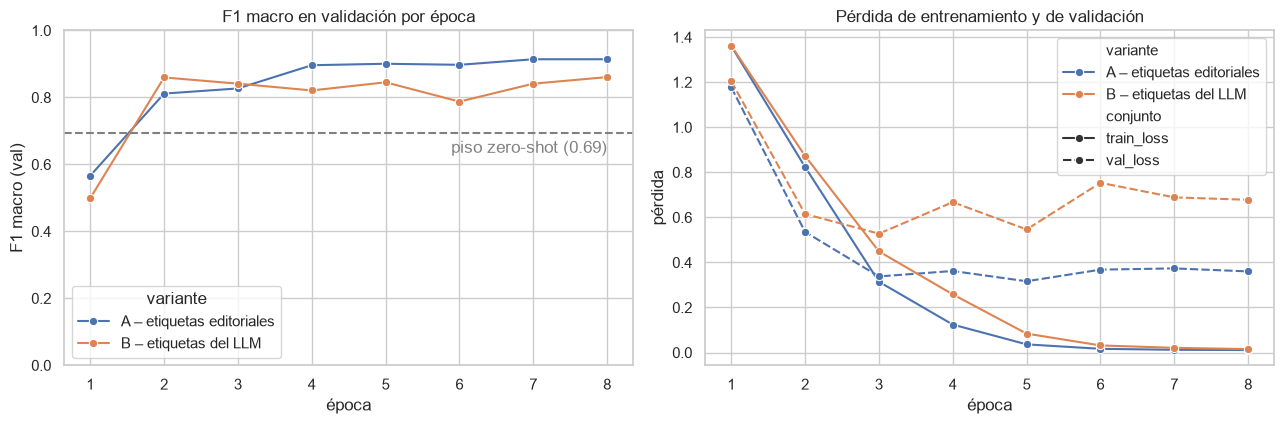

In [13]:
curvas = pd.concat([curva_a.assign(variante="A – etiquetas editoriales"),
                    curva_b.assign(variante="B – etiquetas del LLM")])
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4))
sns.lineplot(data=curvas, x="epoch", y="val_f1_macro", hue="variante", marker="o", ax=ejes[0])
ejes[0].axhline(F1_ZS_40, ls="--", c="grey")
ejes[0].text(EPOCAS, F1_ZS_40 - 0.06, f"piso zero-shot ({F1_ZS_40:.2f})", color="grey", ha="right")
ejes[0].set(title="F1 macro en validación por época", xlabel="época", ylabel="F1 macro (val)", ylim=(0, 1))
sns.lineplot(data=curvas.melt(id_vars=["epoch", "variante"], value_vars=["train_loss", "val_loss"],
                              var_name="conjunto", value_name="pérdida"),
             x="epoch", y="pérdida", hue="variante", style="conjunto", marker="o", ax=ejes[1])
ejes[1].set(title="Pérdida de entrenamiento y de validación", xlabel="época")
plt.tight_layout()
plt.show()

In [14]:
# Se elige por F1 macro en VALIDACIÓN (empate → A, cuyas etiquetas son las editoriales)
val_a = trainer_a.evaluate()["eval_f1_macro"]
val_b = trainer_b.evaluate()["eval_f1_macro"]
VARIANTE = "A" if val_a >= val_b else "B"
elegido = trainer_a if VARIANTE == "A" else trainer_b
print(f"val F1 macro → A: {val_a:.3f} | B: {val_b:.3f} → se guarda la variante {VARIANTE} en {MODELO}/")

for viejo in MODELO.glob("*"):
    if viejo.name != ".gitkeep" and viejo.is_file():
        viejo.unlink()
elegido.save_model(str(MODELO))       # pesos + config + tokenizer
info = {"modelo_base": MODELO_BASE, "variante": VARIANTE,
        "etiquetas_entrenamiento": "etiqueta (editorial)" if VARIANTE == "A" else "etiqueta_llm (supervisión débil)",
        "max_length": MAX_LEN, "epocas": EPOCAS, "batch_size": 16, "learning_rate": 5e-5, "semilla": SEMILLA,
        "val_f1_macro": {"A": round(val_a, 4), "B": round(val_b, 4)},
        "minutos_entrenamiento_cpu": {"A": round(min_a, 1), "B": round(min_b, 1)},
        "n": {p: int((noticias["particion"] == p).sum()) for p in ["train", "val", "test"]}}
(MODELO / "info_entrenamiento.json").write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")
shutil.rmtree(CHECKPOINTS, ignore_errors=True)

pd.DataFrame([{"archivo": f.name, "MB": round(f.stat().st_size / 1e6, 1),
               "va a GitHub": "no (.gitignore)" if f.suffix in {".safetensors", ".bin"} else "sí"}
              for f in sorted(MODELO.iterdir()) if f.is_file() and f.name != ".gitkeep"])

{'eval_loss': '0.3734', 'eval_accuracy': '0.9153', 'eval_f1_macro': '0.914', 'eval_runtime': '11.94', 'eval_samples_per_second': '4.941', 'eval_steps_per_second': '0.167', 'epoch': '8'}


{'eval_loss': '0.6779', 'eval_accuracy': '0.8644', 'eval_f1_macro': '0.8607', 'eval_runtime': '3.231', 'eval_samples_per_second': '18.26', 'eval_steps_per_second': '0.619', 'epoch': '8'}
val F1 macro → A: 0.914 | B: 0.861 → se guarda la variante A en modelo/


,archivo,MB,va a GitHub
0,config.json,0.0,sí
1,info_entrenamiento.json,0.0,sí
2,model.safetensors,541.3,no (.gitignore)
3,tokenizer.json,2.9,sí
4,tokenizer_config.json,0.0,sí
5,training_args.bin,0.0,no (.gitignore)


## 5. Evaluación final en test (paso 5)

Es la **primera vez** que se usan las etiquetas de test. El modelo se carga desde `modelo/` (así se comprueba que lo guardado funciona, igual que lo cargará el dashboard).

In [15]:
tok_final = AutoTokenizer.from_pretrained(MODELO)
modelo_final = AutoModelForSequenceClassification.from_pretrained(MODELO).eval()


@torch.inference_mode()
def predecir(modelo, tokenizer, titulares, lote=32):
    etiquetas, confianzas = [], []
    titulares = list(titulares)
    for i in range(0, len(titulares), lote):
        enc = tokenizer(titulares[i:i + lote], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        prob = torch.softmax(modelo(**enc).logits, dim=-1)
        conf, idx = prob.max(dim=-1)
        etiquetas += [modelo.config.id2label[int(j)] for j in idx]
        confianzas += conf.tolist()
    return etiquetas, confianzas


test = particion("test").copy()
test["pred_ft"], test["conf_ft"] = predecir(modelo_final, tok_final, test["titular"])
M_TEST = metricas(test["etiqueta"], test["pred_ft"])
print(f"TEST (n={len(test)}) | modelo: DistilBERT fine-tuned, variante {VARIANTE}")
print(f"Accuracy = {M_TEST['accuracy']:.3f} | F1 macro = {M_TEST['f1_macro']:.3f}\n")
print(classification_report(test["etiqueta"], test["pred_ft"], labels=ETIQUETAS, digits=3, zero_division=0))

TEST (n=60) | modelo: DistilBERT fine-tuned, variante A
Accuracy = 0.883 | F1 macro = 0.885

                    precision    recall  f1-score   support

          politica      0.812     0.867     0.839        15
          economia      0.812     0.867     0.839        15
          deportes      0.933     0.933     0.933        15
ciencia_tecnologia      1.000     0.867     0.929        15

          accuracy                          0.883        60
         macro avg      0.890     0.883     0.885        60
      weighted avg      0.890     0.883     0.885        60



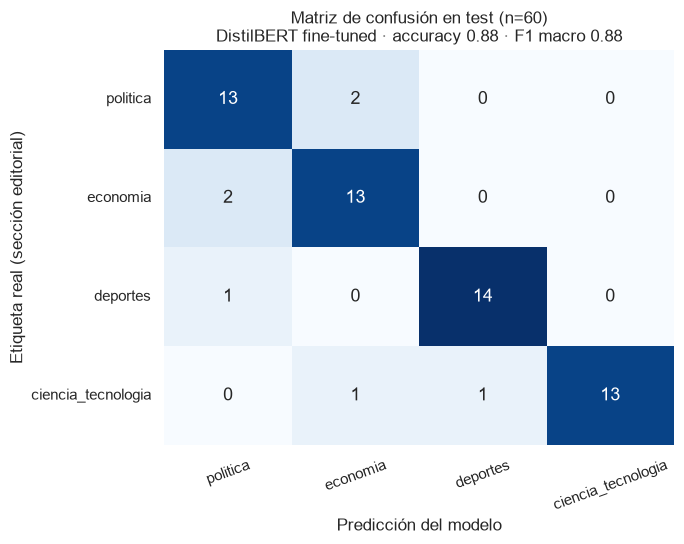

In [16]:
cm = confusion_matrix(test["etiqueta"], test["pred_ft"], labels=ETIQUETAS)
fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=ETIQUETAS, yticklabels=ETIQUETAS,
            annot_kws={"size": 13}, ax=ax)
ax.set(xlabel="Predicción del modelo", ylabel="Etiqueta real (sección editorial)",
       title=f"Matriz de confusión en test (n={len(test)})\n"
             f"DistilBERT fine-tuned · accuracy {M_TEST['accuracy']:.2f} · F1 macro {M_TEST['f1_macro']:.2f}")
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
f1_cat = pd.Series(f1_score(test["etiqueta"], test["pred_ft"], labels=ETIQUETAS, average=None), index=ETIQUETAS)
print("F1 por categoría en test:", f1_cat.round(3).to_dict())
print(f"Mejor: {f1_cat.idxmax()} ({f1_cat.max():.3f}) | peor: {f1_cat.idxmin()} ({f1_cat.min():.3f})")
errores_test = test.loc[test["pred_ft"] != test["etiqueta"], ["etiqueta", "pred_ft", "conf_ft", "titular"]]
print(f"\nErrores en test: {len(errores_test)} de {len(test)}")
errores_test.sort_values("conf_ft", ascending=False).round(3).reset_index(drop=True)

F1 por categoría en test: {'politica': 0.839, 'economia': 0.839, 'deportes': 0.933, 'ciencia_tecnologia': 0.929}
Mejor: deportes (0.933) | peor: politica (0.839)

Errores en test: 7 de 60


,etiqueta,pred_ft,conf_ft,titular
0,deportes,politica,0.992,¿El renacer del básquet peruano? IPD reconoce oficialmente a la nueva Junta Directiva de la FDPB
1,politica,economia,0.990,Viceministra de Minas: “Estamos estableciendo un plazo de 18 meses y no abrimos la puerta a una nueva ampl...
2,ciencia_tecnologia,economia,0.988,"Netflix despedirá a unos 1.000 empleados, el 6 % de su plantilla, según medios"
3,ciencia_tecnologia,deportes,0.984,"Francis Halzen, el nuevo premio nobel de Física, cuenta que usa la IA desde los 90: “Estoy muy orgulloso”"
4,politica,economia,0.956,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ¿que otras medidas in...
5,economia,politica,0.786,"Justin Trudeau, exprimer ministro de Canadá, sobre crisis de turismo en EE.UU.: “No han sido muy buenos ha..."
6,economia,politica,0.759,Vladimir Putin ratifica pacto con Donald Trump para abastecer de crudo a EE.UU. y al mercado internacional


### Reflexión por categoría

El modelo final acierta **53 de 60** noticias de test (accuracy 0.88, **F1 macro 0.88**), 19 puntos sobre el piso zero-shot. Con 60 noticias cada error mueve la accuracy 1.7 puntos; el intervalo de confianza al 95 % es de aproximadamente ±0.08. Aun así, el orden de los modelos coincide con el de validación.

| Categoría | F1 test | Lectura |
|---|---|---|
| **deportes** | **0.93 (mejor)** | Vocabulario cerrado y casi exclusivo: clubes (*Alianza Lima*, *Universitario*), torneos (*Liga 1*, *Clausura*, *Champions*), verbos de resultado (*venció*, *remonta*) y marcadores (*2-1*). Su único error es *"¿El renacer del básquet peruano? IPD reconoce oficialmente a la nueva Junta Directiva de la FDPB"* → `politica`: no hay ningún verbo de juego, sino lenguaje institucional (*reconoce oficialmente*, *Junta Directiva*), y el básquet es raro en un entrenamiento dominado por el fútbol. |
| **ciencia_tecnologia** | 0.93 | **Precisión 1.00**: cuando el modelo dice "ciencia y tecnología" nunca se equivoca, porque marcas y términos como *IA*, *iPhone*, *Google* o *especie* son muy distintivos. Pierde 2 por recall: *"Netflix despedirá a unos 1.000 empleados…"* → `economia` (despidos y plantilla son vocabulario laboral; la nota está en Tecnología solo porque Netflix es una empresa tech) y *"Francis Halzen, el nuevo premio Nobel de Física… 'Estoy muy orgulloso'"* → `deportes` (el formato de entrevista con cita emotiva y logro personal es el típico de los deportistas). |
| **politica** | 0.84 (peor, empatada) | Se confunde **solo con economía**, en ambas direcciones. *"Viceministra de Minas: 'Estamos estableciendo un plazo de 18 meses…'"* y *"Proyecto de Ley MAPE… plantas de beneficio fiscalizadas"* son de la sección Política, pero su tema es minería y formalización, vocabulario económico. |
| **economia** | 0.84 (peor, empatada) | Lo inverso: *"Vladimir Putin ratifica pacto con Donald Trump para abastecer de crudo…"* y *"Justin Trudeau… sobre crisis de turismo en EE.UU."* están en Economía, pero los protagoniza un jefe de Estado y el modelo se guía por el actor político. |

**Causa común de los errores:** en la agenda peruana la política y la economía están entrelazadas (minería, MAPE, aranceles, nombramientos en entidades económicas). El editor archiva por el **tema**; el modelo, con solo ~70 ejemplos por categoría, se guía por el **actor** (ministro, presidente) o por el **formato**. En varios de estos casos una persona también dudaría: parte del "error" es ruido de la etiqueta editorial. Además, los errores tienen **confianza alta (0.76–0.99)**: el modelo está sobreconfiado, algo a considerar al mostrar la probabilidad en el dashboard.

## 6. Comparativa y decisión (paso 6)

Los tres enfoques se miden sobre **las mismas noticias de test** con la misma métrica. Para el costo se reporta el tamaño del modelo, el tiempo por titular en esta CPU y lo que exige ponerlo en marcha.

In [18]:
# Zero-shot (el mejor de la sección 2) sobre el test
clf_zs = pipeline("zero-shot-classification", model=MEJOR_ZS, device=-1)
inicio = time.time()
test["pred_zs"], _ = zero_shot(clf_zs, test["titular"])
seg_zs = (time.time() - inicio) / len(test)
param_zs = sum(p.numel() for p in clf_zs.model.parameters()) / 1e6
del clf_zs
gc.collect()


# Latencia del fine-tuned: un titular a la vez, como en el dashboard
def latencia(modelo, tokenizer, titulares):
    inicio = time.time()
    for t in titulares:
        predecir(modelo, tokenizer, [t])
    return (time.time() - inicio) / len(titulares)


modelo_otro = trainer_b.model if VARIANTE == "A" else trainer_a.model
test["pred_ft_otro"], _ = predecir(modelo_otro.eval(), tok_final, test["titular"])
seg_ft = latencia(modelo_final, tok_final, test["titular"])
param_ft = sum(p.numel() for p in modelo_final.parameters()) / 1e6
otra = "B" if VARIANTE == "A" else "A"
nombre_var = {"A": "etiquetas editoriales", "B": "etiquetas del LLM"}

filas = [
    ("Zero-shot NLI", MEJOR_ZS, test["pred_zs"], param_zs, seg_zs, "Ninguno"),
    ("LLM (supervisión débil)", MODELO_LLM, test["etiqueta_llm"], 1544, meta_llm["seg_por_titular"],
     "Ninguno (solo prompt)"),
    (f"DistilBERT fine-tuned ({VARIANTE}: {nombre_var[VARIANTE]})", MODELO_BASE, test["pred_ft"], param_ft, seg_ft,
     f"{min_a if VARIANTE == 'A' else min_b:.1f} min CPU + {len(particion('train'))} etiquetas"),
    (f"DistilBERT fine-tuned ({otra}: {nombre_var[otra]})", MODELO_BASE, test["pred_ft_otro"], param_ft, seg_ft,
     f"{min_b if VARIANTE == 'A' else min_a:.1f} min CPU + {len(particion('train'))} etiquetas"),
]
comparativa = pd.DataFrame([
    {"enfoque": e, "modelo": m, **metricas(test["etiqueta"], p), "parámetros (M)": round(n),
     "seg/titular (CPU)": s, "entrenamiento": t} for e, m, p, n, s, t in filas
])
comparativa["titulares/min"] = (60 / comparativa["seg/titular (CPU)"]).round(0)
display(comparativa.style.format({"accuracy": "{:.3f}", "f1_macro": "{:.3f}", "seg/titular (CPU)": "{:.3f}",
                                  "titulares/min": "{:,.0f}"}).hide(axis="index"))

enfoque,modelo,accuracy,f1_macro,parámetros (M),seg/titular (CPU),entrenamiento,titulares/min
Zero-shot NLI,joeddav/xlm-roberta-large-xnli,0.700,0.695,560,2.618,Ninguno,23
LLM (supervisión débil),Qwen/Qwen2.5-1.5B-Instruct,0.783,0.779,1544,2.654,Ninguno (solo prompt),23
DistilBERT fine-tuned (A: etiquetas editoriales),distilbert/distilbert-base-multilingual-cased,0.883,0.885,135,0.092,11.0 min CPU + 275 etiquetas,653
DistilBERT fine-tuned (B: etiquetas del LLM),distilbert/distilbert-base-multilingual-cased,0.800,0.801,135,0.092,10.6 min CPU + 275 etiquetas,653


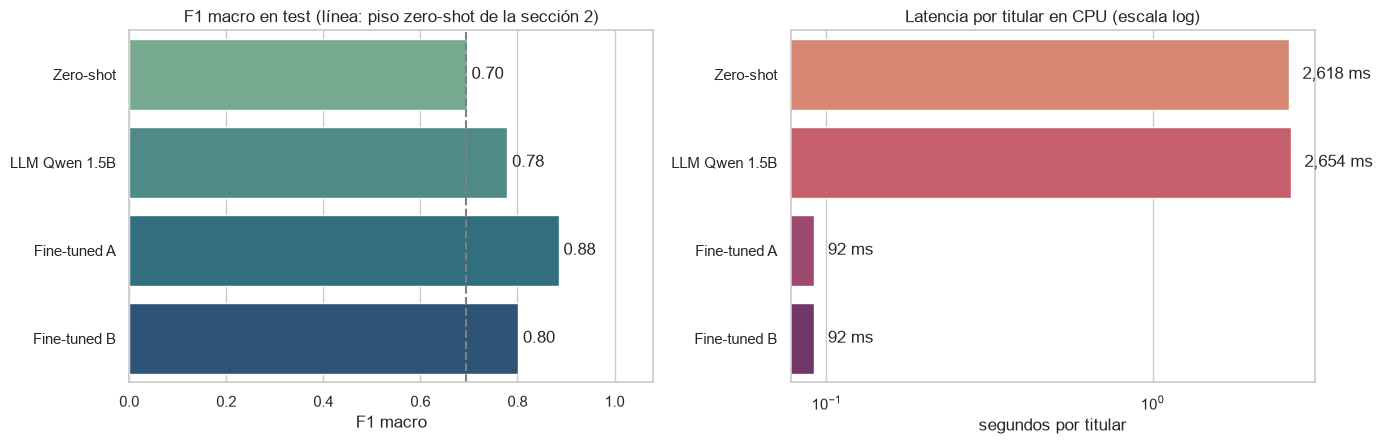

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6))
corto = comparativa.assign(enfoque=["Zero-shot", "LLM Qwen 1.5B", f"Fine-tuned {VARIANTE}", f"Fine-tuned {otra}"])
sns.barplot(data=corto, y="enfoque", x="f1_macro", hue="enfoque", palette="crest", legend=False, ax=ejes[0])
ejes[0].axvline(F1_ZS_40, ls="--", c="grey")
for i, v in enumerate(corto["f1_macro"]):
    ejes[0].text(v + 0.01, i, f"{v:.2f}", va="center")
ejes[0].set(title="F1 macro en test (línea: piso zero-shot de la sección 2)", xlabel="F1 macro", ylabel="", xlim=(0, 1.08))
sns.barplot(data=corto, y="enfoque", x="seg/titular (CPU)", hue="enfoque", palette="flare", legend=False, ax=ejes[1])
ejes[1].set_xscale("log")
for i, v in enumerate(corto["seg/titular (CPU)"]):
    ejes[1].text(v * 1.1, i, f"{v * 1000:,.0f} ms", va="center")
ejes[1].set(title="Latencia por titular en CPU (escala log)", xlabel="segundos por titular", ylabel="")
plt.tight_layout()
plt.show()

### Decisión para un entorno real

**Se elige el DistilBERT fine-tuned (variante A) para producción** (es el que usará el dashboard):

| Criterio | Zero-shot | LLM Qwen 1.5B | **DistilBERT fine-tuned A** |
|---|---|---|---|
| Precisión (F1 macro en test) | 0.70 | 0.78 | **0.88** |
| Latencia por titular (CPU) | ~1.6–2.6 s | ~2.7 s | **~0.07–0.09 s** (≈ 25–40× más rápido) |
| Tamaño / memoria | 560 M parámetros (2.2 GB) | 1.544 M parámetros (6.7 GB de RAM en fp32) | **135 M parámetros (0.54 GB)** |
| Costo de puesta en marcha | ninguno | ninguno (solo prompt) | ~10–11 min de CPU + 275 noticias etiquetadas |
| Costo por titular | alto: 4 inferencias NLI por titular, una por categoría | alto: un modelo de lenguaje de 1.5 B | mínimo: una pasada de un modelo pequeño |

- **Precisión:** es el mejor por amplio margen, en validación (0.91) y en test (0.88).
- **Costo computacional y latencia:** es el más chico y el más rápido; responde en menos de 0.1 s en una CPU de 2012 (los tiempos exactos varían entre ejecuciones según la carga de la PC, pero el orden de magnitud no), así que un dashboard en vivo es viable sin GPU ni APIs de pago. El zero-shot y el LLM tardan segundos por titular y piden de 4 a 12 veces más memoria.
- **El costo del fine-tuning es único** (~11 min) y se amortiza desde la primera consulta.

**¿Para qué sirven los otros dos?**

- El **LLM** no es el mejor clasificador en línea, pero es una **excelente herramienta de etiquetado**. La variante B, entrenada **solo** con sus etiquetas (sin mirar la sección editorial), llega a F1 0.80 en test: supera al propio LLM (0.78) y al zero-shot (0.70), y responde en menos de 0.1 s. Si un medio no tuviera secciones confiables, este sería el camino (*supervisión débil*): etiquetar con el LLM, auditar una muestra y destilar en un modelo pequeño. Lo que separa a B de A (0.80 vs. 0.88) es el costo del ruido de las etiquetas del LLM (51 de 275 difieren de la editorial).
- El **zero-shot** solo se justifica para arrancar sin ningún dato etiquetado.

**Riesgos en producción:**

1. El test es pequeño (60 noticias, ±0.08).
2. Las noticias cambian (las elecciones 2026 dominan hoy la política), así que conviene reentrenar periódicamente con titulares nuevos.
3. Un titular que no pertenece a ninguna de las 4 categorías igual recibe una; como el modelo está sobreconfiado, conviene marcar como "dudosas" las predicciones con probabilidad baja en lugar de mostrarlas como seguras.

In [20]:
# Métricas para el dashboard (Parte 3) y la línea de entrega
resumen = {
    "medio": "El Comercio", "n_noticias": len(noticias), "n_test": len(test),
    "modelo_final": f"DistilBERT multilingüe fine-tuned (variante {VARIANTE})",
    "f1_macro_test": round(M_TEST["f1_macro"], 4), "accuracy_test": round(M_TEST["accuracy"], 4),
    "zero_shot_modelo": MEJOR_ZS, "zero_shot_f1_macro_40": round(F1_ZS_40, 4),
    "zero_shot_f1_macro_test": round(float(comparativa.loc[0, "f1_macro"]), 4),
    "llm_modelo": MODELO_LLM, "llm_f1_macro_test": round(float(comparativa.loc[1, "f1_macro"]), 4),
    "acuerdo_llm_humano": ACUERDO_HUMANO, "auditoria_n": 20,
    "fecha": datetime.now().isoformat(timespec="seconds"),
}
(MODELO / "metricas.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")

acuerdo_txt = f"{ACUERDO_HUMANO}/20" if ACUERDO_HUMANO is not None else "PENDIENTE/20"
print(f"Resultados Test: F1 Macro: {M_TEST['f1_macro']:.2f} | Zero-shot: {F1_ZS_40:.2f} | "
      f"Acuerdo LLM-Humano: {acuerdo_txt}")

Resultados Test: F1 Macro: 0.88 | Zero-shot: 0.69 | Acuerdo LLM-Humano: 19/20


## 7. Resumen de la Parte 2

- **Respuesta a la pregunta guía:** sí. Con 275 titulares de El Comercio, un DistilBERT multilingüe ajustado en ~11 minutos de CPU clasifica titulares nuevos en las 4 categorías con **F1 macro 0.88 en un test nunca visto**, frente a 0.70 del zero-shot y 0.78 del LLM, y en menos de 0.1 s por titular.
- **El LLM como etiquetador:** Qwen2.5-1.5B, local y gratuito, etiquetó los 394 titulares en 17 minutos con salida JSON restringida. Coincide con la sección editorial en el 82 % de los casos, su confianza es informativa (95 % de acuerdo cuando supera 0.95) y en la **auditoría humana acertó 19 de 20 (95 %)**. Un clasificador entrenado solo con sus etiquetas alcanza F1 0.80.
- **Lo más difícil:** separar **política de economía**, que en la agenda peruana comparten actores y temas (minería, MAPE, comercio exterior). **Deportes** es lo más fácil.
- **Rigor:** el test (60 noticias) se apartó antes de todo y no se usó para el prompt, las épocas ni la elección del modelo; todas las decisiones se tomaron con validación o desarrollo.

**Archivos generados:**

| Archivo | Contenido | En GitHub |
|---|---|---|
| `datos/particion.csv` | partición train/val/test por URL | sí |
| `datos/etiquetas_llm.csv` | `titular, etiqueta_llm, confianza, modelo_llm, fecha` (fecha = momento del etiquetado) | sí |
| `datos/etiquetas_llm_meta.json` | modelo, prompt y tiempos del etiquetado | sí |
| `datos/auditoria_llm.csv` | las 20 predicciones auditadas a mano (lo lee el notebook) | sí |
| `datos/auditoria_llm.xlsx` | planilla en la que se hizo la revisión manual | sí |
| `modelo/` | `config.json`, tokenizer, `info_entrenamiento.json`, `metricas.json` | sí |
| `modelo/model.safetensors` | pesos (541 MB) | **no** (`.gitignore`) |